# Anomaly Detection

## 0. Imports and data

We work with NovaShop's daily KPIs. One observation = **one day**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
df = pd.read_csv("novashop_daily_operations.csv", parse_dates=["date"])
print(df.shape)
df.head()

(365, 10)


,date,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets,campaign_active,is_weekend
0,2025-01-01,91,0.0437,135.1400,0.0578,0.0186,473,11,0,0
1,2025-01-02,90,0.0415,142.8400,0.0277,0.0152,409,9,0,0
2,2025-01-03,98,0.0462,146.4200,0.0539,0.0099,387,9,0,0
3,2025-01-04,112,0.0369,140.7900,0.0505,0.0187,564,8,0,1
4,2025-01-05,89,0.0424,147.7300,0.0485,0.0213,495,10,0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  365 non-null    datetime64[us]
 1   orders                365 non-null    int64         
 2   conversion_rate       365 non-null    float64       
 3   avg_order_value       365 non-null    float64       
 4   return_rate           365 non-null    float64       
 5   payment_failure_rate  365 non-null    float64       
 6   site_latency_ms       365 non-null    int64         
 7   support_tickets       365 non-null    int64         
 8   campaign_active       365 non-null    int64         
 9   is_weekend            365 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(5)
memory usage: 28.6 KB


## 1. First, explore the data

Before running a detector, let's examine several KPIs over time.

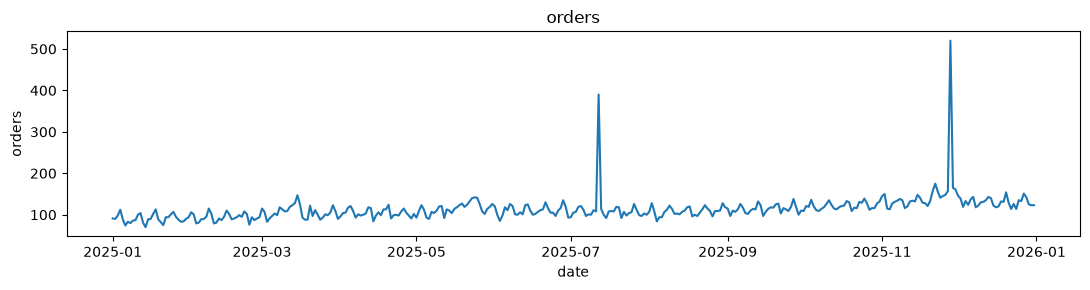

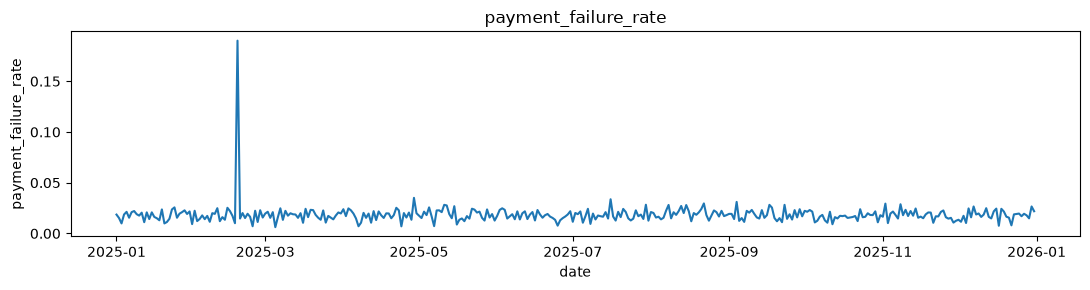

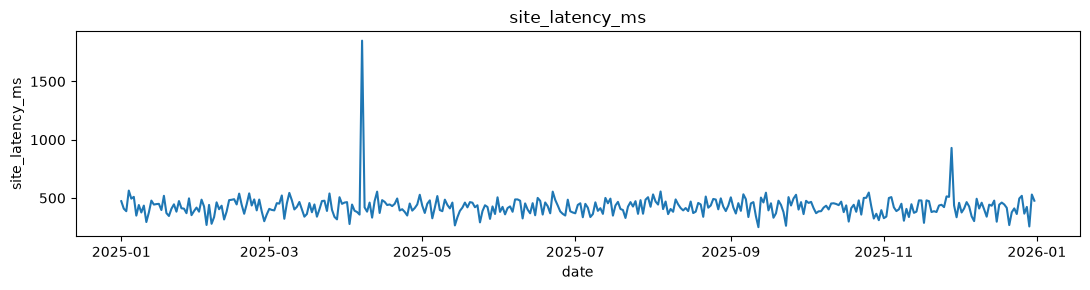

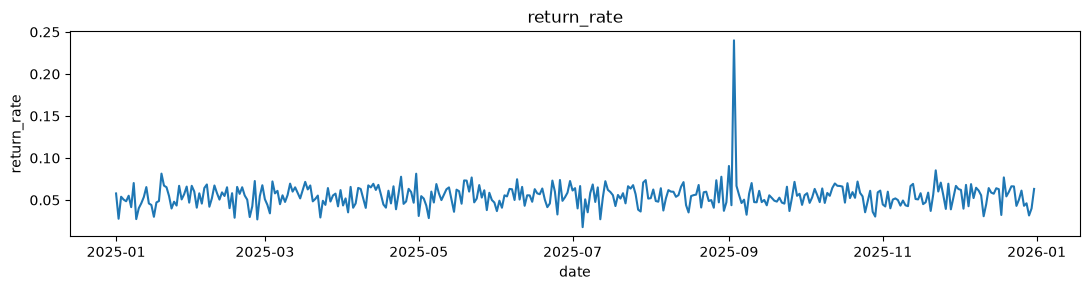

In [4]:
cols = ["orders", "payment_failure_rate", "site_latency_ms", "return_rate"]
for col in cols:
    plt.figure(figsize=(11, 3))
    plt.plot(df["date"], df[col])
    plt.title(col)
    plt.xlabel("date")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 2. LOF in two dimensions

We start with two features to visualize the geometry of the problem. LOF relies on distances, so **we scale the features**.

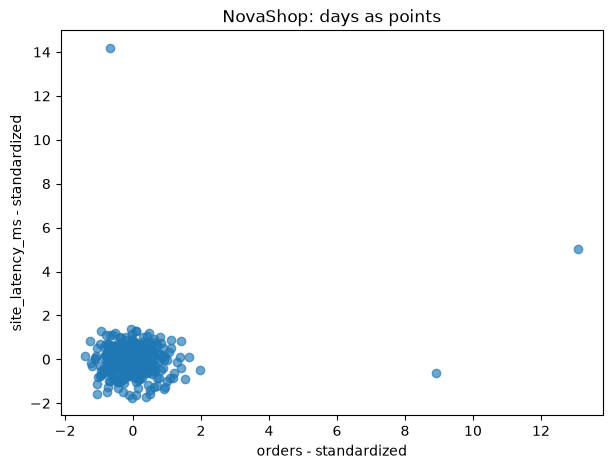

In [5]:
features_2d = ["orders", "site_latency_ms"]
X2 = df[features_2d].copy()
scaler_2d = StandardScaler()
X2_scaled = scaler_2d.fit_transform(X2)

plt.figure(figsize=(7, 5))
plt.scatter(X2_scaled[:, 0], X2_scaled[:, 1], alpha=0.65)
plt.xlabel("orders - standardized")
plt.ylabel("site_latency_ms - standardized")
plt.title("NovaShop: days as points")
plt.show()

In [6]:
lof_2d = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
lof_label_2d = lof_2d.fit_predict(X2_scaled)

# sklearn stores negative_outlier_factor_: more negative values indicate stronger outliers.
# Create an interpretable score: higher values indicate more unusual observations.
lof_score_2d = -lof_2d.negative_outlier_factor_

result_2d = df[["date"] + features_2d].copy()
result_2d["lof_score"] = lof_score_2d
result_2d["lof_anomaly"] = lof_label_2d == -1
result_2d.sort_values("lof_score", ascending=False).head(10)

,date,orders,site_latency_ms,lof_score,lof_anomaly
96,2025-04-07,93,1850,28.3703,True
331,2025-11-28,520,930,20.8047,True
192,2025-07-12,390,364,11.7586,True
325,2025-11-22,175,380,1.9312,True
215,2025-08-04,84,556,1.8694,True
34,2025-02-04,81,269,1.8226,True
5,2025-01-06,74,510,1.8112,True
13,2025-01-14,70,444,1.7208,True
330,2025-11-27,157,510,1.7154,False
332,2025-11-29,165,437,1.6581,False


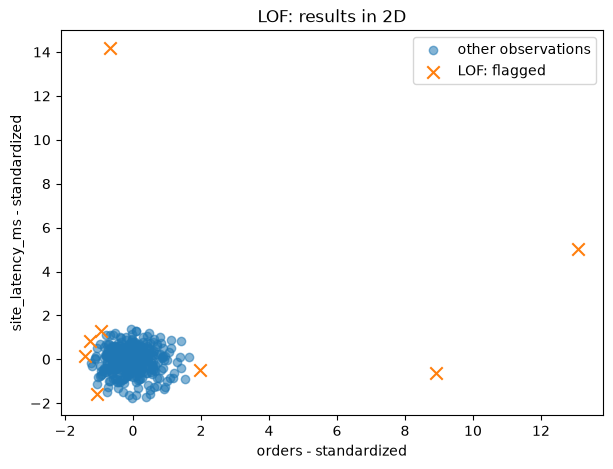

In [7]:
plt.figure(figsize=(7, 5))
normal = ~result_2d["lof_anomaly"]
anom = result_2d["lof_anomaly"]
plt.scatter(X2_scaled[normal, 0], X2_scaled[normal, 1], alpha=0.55, label="other observations")
plt.scatter(X2_scaled[anom, 0], X2_scaled[anom, 1], s=80, marker="x", label="LOF: flagged")
plt.xlabel("orders - standardized")
plt.ylabel("site_latency_ms - standardized")
plt.title("LOF: results in 2D")
plt.legend()
plt.show()

### Interpretation
1. Are all flagged days simply the largest values on the X or Y axis?
2. Can you find a point whose unusualness results from **its position relative to its neighbors**?

## 3. What changes when we vary the number of neighbors?

We are not looking for the 'best k'. We want to see how changing the neighborhood changes the definition of locality.

In [8]:
lof_k = pd.DataFrame({"date": df["date"]})
for k in [5, 10, 20, 40]:
    model = LocalOutlierFactor(n_neighbors=k, contamination=0.02)
    model.fit_predict(X2_scaled)
    lof_k[f"score_k{k}"] = -model.negative_outlier_factor_

lof_k.head()

,date,score_k5,score_k10,score_k20,score_k40
0,2025-01-01,1.1340,1.0515,1.0616,1.0501
1,2025-01-02,1.1190,1.1331,1.0557,1.0467
2,2025-01-03,1.0262,1.0036,0.9851,0.9943
3,2025-01-04,1.4787,1.4531,1.4755,1.5646
4,2025-01-05,1.0853,1.2065,1.2680,1.2114


In [9]:
for col in ["score_k5", "score_k10", "score_k20", "score_k40"]:
    top = lof_k.nlargest(5, col)[["date", col]]
    print(f"\nTOP 5 for {col}")
    print(top.to_string(index=False))


TOP 5 for score_k5
      date  score_k5
2025-04-07   35.6691
2025-11-28   17.5116
2025-07-12   12.6495
2025-01-08    1.9058
2025-11-27    1.7669

TOP 5 for score_k10
      date  score_k10
2025-04-07    29.2467
2025-11-28    20.5295
2025-07-12    11.9912
2025-02-04     1.8457
2025-01-14     1.8087

TOP 5 for score_k20
      date  score_k20
2025-04-07    28.3703
2025-11-28    20.8047
2025-07-12    11.7586
2025-11-22     1.9312
2025-08-04     1.8694

TOP 5 for score_k40
      date  score_k40
2025-04-07    25.1584
2025-11-28    20.9106
2025-07-12    11.9064
2025-11-22     2.0698
2025-08-04     1.9359


**Question:** Which days consistently rank high regardless of `n_neighbors`, and which appear only when using a very local perspective?

## 4. Isolation Forest - a different definition of unusualness

Now we use more features simultaneously. Unlike LOF, this model does not compare local densities.

In [12]:
features = [
    "orders",
    "conversion_rate",
    "avg_order_value",
    "return_rate",
    "payment_failure_rate",
    "site_latency_ms",
    "support_tickets",
]

X = df[features].copy()
X.describe().T

,count,mean,std,min,25%,50%,75%,max
orders,365.0000,113.5616,31.0613,70.0000,100.0000,111.0000,123.0000,520.0000
conversion_rate,365.0000,0.0456,0.0045,0.0210,0.0434,0.0457,0.0478,0.0790
avg_order_value,365.0000,145.3363,7.7637,124.8300,140.6100,145.4200,149.9000,188.0000
return_rate,365.0000,0.0548,0.0151,0.0177,0.0466,0.0551,0.0631,0.2400
payment_failure_rate,365.0000,0.0185,0.0102,0.0062,0.0150,0.0180,0.0214,0.1900
site_latency_ms,365.0000,426.8219,100.4783,250.0000,381.0000,426.0000,465.0000,1850.0000
support_tickets,365.0000,10.0192,3.6408,4.0000,8.0000,10.0000,11.0000,44.0000


In [13]:
iso = IsolationForest(
    n_estimators=300,
    contamination=0.02,
    random_state=42
)
iso.fit(X)

# score_samples: higher values indicate more normal observations. We reverse the sign for consistency.
df_result = df.copy()
df_result["if_anomaly_score"] = -iso.score_samples(X)
df_result["if_anomaly"] = iso.predict(X) == -1

df_result.sort_values("if_anomaly_score", ascending=False)[
    ["date", "if_anomaly_score", "if_anomaly"] + features
].head(12)

,date,if_anomaly_score,if_anomaly,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets
331,2025-11-28,0.7698,True,520,0.0790,161.7400,0.0389,0.0154,930,19
48,2025-02-18,0.7517,True,91,0.0210,138.6100,0.0656,0.1900,442,38
96,2025-04-07,0.7297,True,93,0.0240,135.8800,0.0644,0.0071,1850,31
245,2025-09-03,0.6788,True,110,0.0442,146.5400,0.2400,0.0142,367,44
192,2025-07-12,0.6499,True,390,0.0449,188.0000,0.0271,0.0170,364,6
325,2025-11-22,0.5979,True,175,0.0523,160.6000,0.0853,0.0169,380,19
332,2025-11-29,0.5219,True,165,0.0552,150.3500,0.0529,0.0107,437,15
269,2025-09-27,0.5088,True,138,0.0509,153.5300,0.0716,0.0230,528,17
243,2025-09-01,0.5039,False,115,0.0353,143.9100,0.0905,0.0193,506,6
19,2025-01-20,0.4981,False,82,0.0372,133.1400,0.0671,0.0099,346,5


### Do not look only at the flag
First, examine the ranking. For the 3-5 highest-scoring days, try to explain **what exactly makes them unusual**.

In [14]:
top_if = df_result.nlargest(10, "if_anomaly_score")
top_if[["date", "if_anomaly_score"] + features]

,date,if_anomaly_score,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets
331,2025-11-28,0.7698,520,0.0790,161.7400,0.0389,0.0154,930,19
48,2025-02-18,0.7517,91,0.0210,138.6100,0.0656,0.1900,442,38
96,2025-04-07,0.7297,93,0.0240,135.8800,0.0644,0.0071,1850,31
245,2025-09-03,0.6788,110,0.0442,146.5400,0.2400,0.0142,367,44
192,2025-07-12,0.6499,390,0.0449,188.0000,0.0271,0.0170,364,6
325,2025-11-22,0.5979,175,0.0523,160.6000,0.0853,0.0169,380,19
332,2025-11-29,0.5219,165,0.0552,150.3500,0.0529,0.0107,437,15
269,2025-09-27,0.5088,138,0.0509,153.5300,0.0716,0.0230,528,17
243,2025-09-01,0.5039,115,0.0353,143.9100,0.0905,0.0193,506,6
19,2025-01-20,0.4981,82,0.0372,133.1400,0.0671,0.0099,346,5


## 5. `contamination`: the data stay the same, but the threshold changes

Compare the number of flagged observations for the same dataset.

In [15]:
contamination_results = []
for contamination in [0.01, 0.02, 0.05, 0.10]:
    m = IsolationForest(
        n_estimators=300,
        contamination=contamination,
        random_state=42
    )
    labels = m.fit_predict(X)
    contamination_results.append({
        "contamination": contamination,
        "n_flagged": int((labels == -1).sum())
    })

pd.DataFrame(contamination_results)

,contamination,n_flagged
0,0.0100,4
1,0.0200,8
2,0.0500,19
3,0.1000,37


## 6. LOF and Isolation Forest using the same feature representation

For a fairer comparison, both models receive the same set of features. We scale the features for LOF.

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
lof_labels = lof.fit_predict(X_scaled)

comparison = df[["date"]].copy()
comparison["lof_score"] = -lof.negative_outlier_factor_
comparison["lof_anomaly"] = lof_labels == -1
comparison["if_score"] = df_result["if_anomaly_score"]
comparison["if_anomaly"] = df_result["if_anomaly"]
comparison["agreement"] = comparison["lof_anomaly"] == comparison["if_anomaly"]

comparison.sort_values(["lof_anomaly", "if_anomaly"], ascending=False).head(15)

,date,lof_score,lof_anomaly,if_score,if_anomaly,agreement
48,2025-02-18,11.4704,True,0.7517,True,True
96,2025-04-07,10.5197,True,0.7297,True,True
192,2025-07-12,5.4288,True,0.6499,True,True
245,2025-09-03,8.7414,True,0.6788,True,True
325,2025-11-22,2.0059,True,0.5979,True,True
331,2025-11-28,8.0684,True,0.7698,True,True
185,2025-07-05,1.5180,True,0.4683,False,False
243,2025-09-01,1.6176,True,0.5039,False,False
269,2025-09-27,1.4880,False,0.5088,True,False
332,2025-11-29,1.4516,False,0.5219,True,False


In [17]:
pd.crosstab(
    comparison["lof_anomaly"],
    comparison["if_anomaly"],
    rownames=["LOF"],
    colnames=["Isolation Forest"]
)

Isolation Forest,False,True
LOF,,
False,355,2
True,2,6


### Discussion
- Which days are flagged by both models?
- Which are flagged by only one model?
- Does disagreement mean that one model is wrong?
- What characteristics do the cases of disagreement have?

In [18]:
flagged = comparison[comparison["lof_anomaly"] | comparison["if_anomaly"]]
flagged.merge(df[["date"] + features], on="date").sort_values(
    ["lof_anomaly", "if_anomaly"], ascending=False
)

,date,lof_score,lof_anomaly,if_score,if_anomaly,agreement,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets
0,2025-02-18,11.4704,True,0.7517,True,True,91,0.0210,138.6100,0.0656,0.1900,442,38
1,2025-04-07,10.5197,True,0.7297,True,True,93,0.0240,135.8800,0.0644,0.0071,1850,31
3,2025-07-12,5.4288,True,0.6499,True,True,390,0.0449,188.0000,0.0271,0.0170,364,6
5,2025-09-03,8.7414,True,0.6788,True,True,110,0.0442,146.5400,0.2400,0.0142,367,44
7,2025-11-22,2.0059,True,0.5979,True,True,175,0.0523,160.6000,0.0853,0.0169,380,19
8,2025-11-28,8.0684,True,0.7698,True,True,520,0.0790,161.7400,0.0389,0.0154,930,19
2,2025-07-05,1.5180,True,0.4683,False,False,121,0.0487,134.6000,0.0177,0.0106,450,11
4,2025-09-01,1.6176,True,0.5039,False,False,115,0.0353,143.9100,0.0905,0.0193,506,6
6,2025-09-27,1.4880,False,0.5088,True,False,138,0.0509,153.5300,0.0716,0.0230,528,17
9,2025-11-29,1.4516,False,0.5219,True,False,165,0.0552,150.3500,0.0529,0.0107,437,15


## 7. Context: `campaign_active` and `is_weekend`

A detector may flag a statistically unusual day that makes sense once context is considered.

In [19]:
flagged_context = flagged.merge(
    df[["date", "campaign_active", "is_weekend"] + features],
    on="date"
)
flagged_context.sort_values("if_score", ascending=False)

,date,lof_score,lof_anomaly,if_score,if_anomaly,agreement,campaign_active,is_weekend,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets
8,2025-11-28,8.0684,True,0.7698,True,True,1,0,520,0.0790,161.7400,0.0389,0.0154,930,19
0,2025-02-18,11.4704,True,0.7517,True,True,0,0,91,0.0210,138.6100,0.0656,0.1900,442,38
1,2025-04-07,10.5197,True,0.7297,True,True,0,0,93,0.0240,135.8800,0.0644,0.0071,1850,31
5,2025-09-03,8.7414,True,0.6788,True,True,0,0,110,0.0442,146.5400,0.2400,0.0142,367,44
3,2025-07-12,5.4288,True,0.6499,True,True,0,1,390,0.0449,188.0000,0.0271,0.0170,364,6
7,2025-11-22,2.0059,True,0.5979,True,True,1,1,175,0.0523,160.6000,0.0853,0.0169,380,19
9,2025-11-29,1.4516,False,0.5219,True,False,1,1,165,0.0552,150.3500,0.0529,0.0107,437,15
6,2025-09-27,1.4880,False,0.5088,True,False,0,1,138,0.0509,153.5300,0.0716,0.0230,528,17
4,2025-09-01,1.6176,True,0.5039,False,False,0,0,115,0.0353,143.9100,0.0905,0.0193,506,6
2,2025-07-05,1.5180,True,0.4683,False,False,0,1,121,0.0487,134.6000,0.0177,0.0106,450,11


**Question:** Should a campaign day automatically be treated as a 'problem'? What changes when you know that an observation comes from Black Friday or another event?

# 8. Revealing the `ground truth`

In [20]:
key = pd.read_csv("INSTRUCTOR_anomaly_key.csv", parse_dates=["date"])
key[key["known_anomaly"] == 1]

,date,known_anomaly,anomaly_type
48,2025-02-18,1,awaria płatności
96,2025-04-07,1,problem wydajności
192,2025-07-12,1,nietypowy pik sprzedaży
245,2025-09-03,1,fala zwrotów
331,2025-11-28,1,Black Friday - anomalia kontekstowa


In [21]:
evaluation = comparison.merge(key, on="date")
known = evaluation[evaluation["known_anomaly"] == 1].merge(
    df[["date"] + features + ["campaign_active", "is_weekend"]], on="date"
)
known[[
    "date", "anomaly_type", "lof_anomaly", "if_anomaly",
    "lof_score", "if_score", "campaign_active", "is_weekend"
] + features]

,date,anomaly_type,lof_anomaly,if_anomaly,lof_score,if_score,campaign_active,is_weekend,orders,conversion_rate,avg_order_value,return_rate,payment_failure_rate,site_latency_ms,support_tickets
0,2025-02-18,awaria płatności,True,True,11.4704,0.7517,0,0,91,0.0210,138.6100,0.0656,0.1900,442,38
1,2025-04-07,problem wydajności,True,True,10.5197,0.7297,0,0,93,0.0240,135.8800,0.0644,0.0071,1850,31
2,2025-07-12,nietypowy pik sprzedaży,True,True,5.4288,0.6499,0,1,390,0.0449,188.0000,0.0271,0.0170,364,6
3,2025-09-03,fala zwrotów,True,True,8.7414,0.6788,0,0,110,0.0442,146.5400,0.2400,0.0142,367,44
4,2025-11-28,Black Friday - anomalia kontekstowa,True,True,8.0684,0.7698,1,0,520,0.0790,161.7400,0.0389,0.0154,930,19


In [22]:
summary = pd.DataFrame({
    "model": ["LOF", "Isolation Forest"],
    "flagged_total": [evaluation["lof_anomaly"].sum(), evaluation["if_anomaly"].sum()],
    "known_anomalies_detected": [
        ((evaluation["lof_anomaly"]) & (evaluation["known_anomaly"] == 1)).sum(),
        ((evaluation["if_anomaly"]) & (evaluation["known_anomaly"] == 1)).sum(),
    ]
})
summary

,model,flagged_total,known_anomalies_detected
0,LOF,8,5
1,Isolation Forest,8,5
